# CS430 Assignment 3
## Bemjamin Valenzuela
### 11/8/26

Import Libraries

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import sklearn
from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
print("scikit-learn version:", sklearn.__version__)
drive.mount('/content/drive')
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/SLCM_rent_arrears_student_clean.csv")

scikit-learn version: 1.6.1
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


P1 - 1

In [ ]:
display(df.head())
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.isna().sum().rename("Missing values").to_frame())

,record_id,adults_in_household,children_in_household,household_has_65plus,monthly_household_income,income_sources,employment_status,has_housing_voucher,eviction_in_progress,behind_on_utilities,main_reason_behind_on_rent,intake_quarter,monthly_rent,past_due_rent
0,SLCM_0001,1,1,No,293.0,"Food benefits - TANF/SNAP, No income, Other",Unemployed but want to find work,No,I don't know,Yes,Other,2026-Q1,1560.0,3100.0
1,SLCM_0002,0,3,No,2000.0,Child support,Employed,No,I don't know,Yes,Unexpected expense,2026-Q3,1550.0,7300.0
2,SLCM_0003,1,0,No,400.0,Food benefits - TANF/SNAP,Unemployed but want to find work,I don't know,Yes,Yes,Lost a job/had hours cut,2025-Q4,0.0,6000.0
3,SLCM_0004,2,0,No,2500.0,Full-time employment,Unemployed and not looking for work,No,Yes,Yes,Lost a job/had hours cut,2026-Q2,1299.0,2500.0
4,SLCM_0005,1,2,No,14.0,Part-time employment,Employed,No,Yes,No,Unexpected expense,2025-Q4,1105.5,1205.5


Shape: (1754, 14)
Columns: ['record_id', 'adults_in_household', 'children_in_household', 'household_has_65plus', 'monthly_household_income', 'income_sources', 'employment_status', 'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter', 'monthly_rent', 'past_due_rent']


,Missing values
record_id,0
adults_in_household,0
children_in_household,0
household_has_65plus,0
monthly_household_income,108
income_sources,0
employment_status,0
has_housing_voucher,0
eviction_in_progress,1
behind_on_utilities,7


There are 1,754 rows and 14 columns, with the most missing values in monthly household income, 108. Monthly rent is numerical, while employment status is categorical. Past due rent must be excluded because it directly defines the target; using it would leak the answer into the predictors.

P1-2

,count
high_arrears,
0,1210
1,544


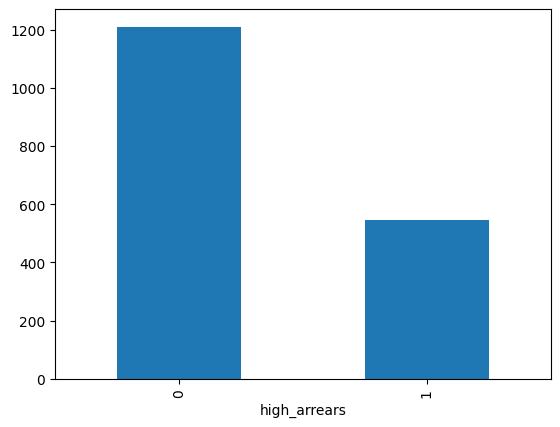

In [ ]:
#Create high_arrears: 1 if past_due_rent is at least $3,000, otherwise 0.
#Show class counts and one bar chart of high_arrears.
df["high_arrears"] = (df["past_due_rent"] >= 3000).astype(int)
display(df["high_arrears"].value_counts())
df["high_arrears"].value_counts().plot(kind="bar")
plt.show()

Class 0 is larger, about 1,210 households, compared with 544 in class 1. A model that always predicts class 0 would achieve about 69% accuracy, while missing every high-arrears household, so recall and F1 are essential in this cas

P2-3

In [ ]:
#Create X by dropping record_id, past_due_rent, and high_arrears. Set y = high_arrears.
# Split the data once into training and testing sets.
X = df.drop(columns=["record_id", "past_due_rent", "high_arrears"])
y = df["high_arrears"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training shape:", X_train.shape, "Test shape:", X_test.shape)
display(pd.DataFrame({"Train": y_train.value_counts(), "Test": y_test.value_counts()}).sort_index())

Training shape: (1403, 12) Test shape: (351, 12)


,Train,Test
high_arrears,,
0,968,242
1,435,109


The split reserves 351 households for testing and uses 1,403 for training. Using stratification preserves the approximate class proportions. A separate test set estimates how the fitted models perform on unseen households, instead of measuring how well they reproduce their training data.

P2-4

In [ ]:
#Identify numerical and categorical columns with select_dtypes.
numeric_columns = X_train.select_dtypes(include="number").columns.tolist()
categorical_columns = X_train.select_dtypes(exclude="number").columns.tolist()
#Numerical: fill missing values using median and apply StandardScaler.
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
#Categorical: fill missing values using most_frequent and apply OneHotEncoder(handle_unknown="ignore").
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
#Combine with ColumnTransformer. You may reuse the class example
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])
#print num + cat
print("Numerical:", numeric_columns)
print("Categorical:", categorical_columns)

Numerical: ['adults_in_household', 'children_in_household', 'monthly_household_income', 'monthly_rent']
Categorical: ['household_has_65plus', 'income_sources', 'employment_status', 'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter']


Scaling keeps high numeerical values (namely dollar-valued features) from dominating KNN and SVC because their units are larger, and both models are sensitive to massive numbers such as dollar values.

p3-5

In [ ]:
results = []
predictions = {}
lr = Pipeline([("preprocessor", clone(preprocessor)), ("model", LogisticRegression(max_iter=1000))])
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)
predictions["Logistic Regression"] = lr_pred
lr_scores = {"Model": "Logistic Regression", "Accuracy": accuracy_score(y_test, lr_pred),
             "Recall": recall_score(y_test, lr_pred, pos_label=1, zero_division=0),
             "F1": f1_score(y_test, lr_pred, pos_label=1, zero_division=0)}
results.append(lr_scores)
display(pd.DataFrame([lr_scores]).round(4))

,Model,Accuracy,Recall,F1
0,Logistic Regression,0.6952,0.3028,0.3815


In [ ]:
knn = Pipeline([("preprocessor", clone(preprocessor)), ("model", KNeighborsClassifier(n_neighbors=5))])
knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)
predictions["KNN"] = knn_pred
knn_scores = {"Model": "KNN", "Accuracy": accuracy_score(y_test, knn_pred),
             "Recall": recall_score(y_test, knn_pred, pos_label=1, zero_division=0),
             "F1": f1_score(y_test, knn_pred, pos_label=1, zero_division=0)}
results.append(knn_scores)
display(pd.DataFrame([knn_scores]).round(4))

,Model,Accuracy,Recall,F1
0,KNN,0.6809,0.3761,0.4227


In [ ]:
dt = Pipeline([("preprocessor", clone(preprocessor)), ("model", DecisionTreeClassifier(max_depth=5, random_state=42))])
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)
predictions["Decision Tree"] = dt_pred
dt_scores = {"Model": "Decision Tree", "Accuracy": accuracy_score(y_test, dt_pred),
             "Recall": recall_score(y_test, dt_pred, pos_label=1, zero_division=0),
             "F1": f1_score(y_test, dt_pred, pos_label=1, zero_division=0)}
results.append(dt_scores)
display(pd.DataFrame([dt_scores]).round(4))

,Model,Accuracy,Recall,F1
0,Decision Tree,0.6952,0.3303,0.4022


In [ ]:
rf = Pipeline([("preprocessor", clone(preprocessor)), ("model", RandomForestClassifier(n_estimators=100, random_state=42))])
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
predictions["Random Forest"] = rf_pred
rf_scores = {"Model": "Random Forest", "Accuracy": accuracy_score(y_test, rf_pred),
             "Recall": recall_score(y_test, rf_pred, pos_label=1, zero_division=0),
             "F1": f1_score(y_test, rf_pred, pos_label=1, zero_division=0)}
results.append(rf_scores)
display(pd.DataFrame([rf_scores]).round(4))

,Model,Accuracy,Recall,F1
0,Random Forest,0.7037,0.3211,0.4023


In [ ]:
svc = Pipeline([("preprocessor", clone(preprocessor)), ("model", SVC())])
svc.fit(X_train, y_train)
svc_pred = svc.predict(X_test)
predictions["SVC"] = svc_pred
svc_scores = {"Model": "SVC", "Accuracy": accuracy_score(y_test, svc_pred),
             "Recall": recall_score(y_test, svc_pred, pos_label=1, zero_division=0),
             "F1": f1_score(y_test, svc_pred, pos_label=1, zero_division=0)}
results.append(svc_scores)
display(pd.DataFrame([svc_scores]).round(4))

,Model,Accuracy,Recall,F1
0,SVC,0.7066,0.2294,0.3268


P3-6

,Model,Accuracy,Recall,F1
0,Logistic Regression,0.6952,0.3028,0.3815
1,KNN,0.6809,0.3761,0.4227
2,Decision Tree,0.6952,0.3303,0.4022
3,Random Forest,0.7037,0.3211,0.4023
4,SVC,0.7066,0.2294,0.3268


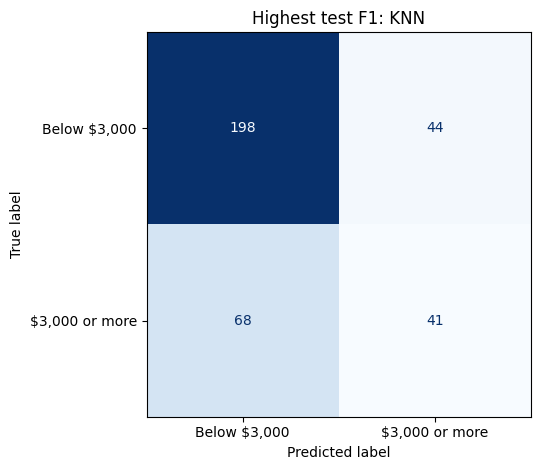

True negatives: 198 False positives: 44 False negatives: 68 True positives: 41


In [ ]:
comparison = pd.DataFrame(results)
display(comparison.round(4))
best_name = comparison.loc[comparison["F1"].idxmax(), "Model"]
best_predictions = predictions[best_name]
cm = confusion_matrix(y_test, best_predictions, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=["Below $3,000", "$3,000 or more"]).plot(cmap="Blues", colorbar=False)
plt.title(f"Highest test F1: {best_name}")
plt.tight_layout()
plt.show()
tn, fp, fn, tp = cm.ravel()
print("True negatives:", tn, "False positives:", fp, "False negatives:", fn, "True positives:", tp)

KNN has both the highest test F1 of  0.4227 and the highest recall at 37.61%, catching 41 of 109 high-arrears households. Its confusion matrix shows 198 true negatives, 44 false positives, 68 false negatives, and 41 true positives. For SLCM, a missed case is a household with at least $3,000 in overdue rent predicted to be below that threshold, which could lead to missed outreach if staff relied on the model.

P3-7

In [ ]:
knn_search = GridSearchCV(clone(knn), {"model__n_neighbors": [3, 5, 7]}, cv=3, scoring="f1")
knn_search.fit(X_train, y_train)
print("KNN best_params_:", knn_search.best_params_)
print("KNN best_score_:", knn_search.best_score_)

rf_search = GridSearchCV(clone(rf), {"model__max_depth": [3, 5, None]}, cv=3, scoring="f1")
rf_search.fit(X_train, y_train)
print("Random Forest best_params_:", rf_search.best_params_)
print("Random Forest best_score_:", rf_search.best_score_)

KNN has the higher best cross-validation F1: 0.4855 with 7 neighbors, compared with 0.4575 for Random Forest with max_depth=None. GridSearchCV is fitted only on training data so the test set cannot influence hyperparameter selectio.Additionally, putting preprocessing inside each searched pipeline also prevents validation-fold information from leaking into training.

P4-8

Of all five models, KNN is the most promising, as it produced the highest F1 value of 0.4227 and Recall of 37.61%. While it may have a comparably lower accuracy of 68.18%, its recall catches the most households in the target group. More complex models did not necessarily perform better since Random Forest and SVC both had lower F1 and recall than the KNN model. Most critically, SLCM should pay particular attention to false negatives, since KNN missed 68 of 109 high-arrears households, while its 44 false positives could also direct limited outreach resources toward households below the threshold.

P4-9


We compared five methods to identify households with at least $3,000 in past due rent using household and housing information. The strongest method by our main comparison was KNN. It correctly classified about 68% of the test households and identified 41 of the 109 households with high arrears. This suggests that predictions might help staff flag some households for follow-up, but a low-risk prediction should never be taken as evidence that a household does not need help as the method can erroneously flag households as not in need of assistance. A major limitation is that the model missed 68 high-arrears households, and results from this one sample may not carry over to future applicants. A prediction is not proof of cause and must not be used alone to decide eligibility for assistance.